# Multi-head looped transformer experiments

# My Custom Experiments

In the previous sections I have attempted to re-produce experiments from Gatmiry et al. In the following sections, I will implement several experiments that apply different assumptions and test the theoretical bounds of this paper. These were not written in the original paper.

In [ ]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from experiments_helper import (
    run_experiment_suite,
    compute_loss_dict,
    compute_dist_dict,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [ ]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

# Multi-head looped transformer sweep

Train only the shared-weight looped transformer on the same Gaussian regression task while sweeping the number of attention heads over [1, 2, 4, 8]. This mirrors the original depth/loop experiment, but now the architecture is allowed to vary in width instead of type. The run uses the same seeds, loop counts, context length, and training setup as the baseline, and stores the resulting histories and test losses for comparison across head counts.

In [ ]:
# --- Multi-head looped transformer sweep ---

multihead_seeds = [0, 1, 2]
multihead_loop_counts = [2, 5]
multihead_model_types = ['looped']
multihead_head_counts = [1, 2, 4]
multihead_context_lengths = [N]
multihead_filename = os.path.join(cur_dir, f'looped_multihead_N{N}_d{d}_histories.pth')
multihead_results_file = os.path.join(cur_dir, f'looped_multihead_N{N}_d{d}_results.pth')

multihead_hist_dict = run_experiment_suite(
    seeds=multihead_seeds,
    n_layers_loops=multihead_loop_counts,
    model_types=multihead_model_types,
    filename=multihead_filename,
    context_lengths=multihead_context_lengths,
    data_modes=[normal_data_mode],
    head_counts=multihead_head_counts,
)

multihead_loss_dict = compute_loss_dict(
    multihead_hist_dict,
    test_seed=TEST_SEED,
    data_mode=normal_data_mode,
)

torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': multihead_seeds, 'loop_counts': multihead_loop_counts,
        'model_types': multihead_model_types, 'head_counts': multihead_head_counts,
        'context_lengths': multihead_context_lengths, 'data_mode': normal_data_mode,
        'test_seed': TEST_SEED,
    },
    'hist_dict': multihead_hist_dict,
    'loss_dict': multihead_loss_dict,
}, multihead_results_file)

print(f'Saved multi-head looped sweep results to {multihead_results_file}')


Run 1/6: seed=0, count=2, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1
iter 0 | Loss: 5.184084415435791 | time: 0.004908323287963867 | gradnorm: 6.713540554046631
iter 1 | Loss: 4.863616943359375 | time: 0.004140377044677734 | gradnorm: 6.63913631439209
iter 2 | Loss: 5.026864528656006 | time: 0.004330873489379883 | gradnorm: 6.909933567047119
iter 3 | Loss: 4.822576522827148 | time: 0.005481243133544922 | gradnorm: 6.9354119300842285
iter 4 | Loss: 4.920429229736328 | time: 0.004513263702392578 | gradnorm: 7.037217617034912
iter 100 | Loss: 3.4544289112091064 | time: 0.004328012466430664 | gradnorm: 5.220376491546631
iter 200 | Loss: 2.650038242340088 | time: 0.004304170608520508 | gradnorm: 3.9534597396850586
iter 300 | Loss: 1.97808039188385 | time: 0.003993034362792969 | gradnorm: 2.7030904293060303
iter 400 | Loss: 1.5920723676681519 | time: 0.003999948501586914 | gradnorm: 1.5670084953308105
iter 500 | Loss: 

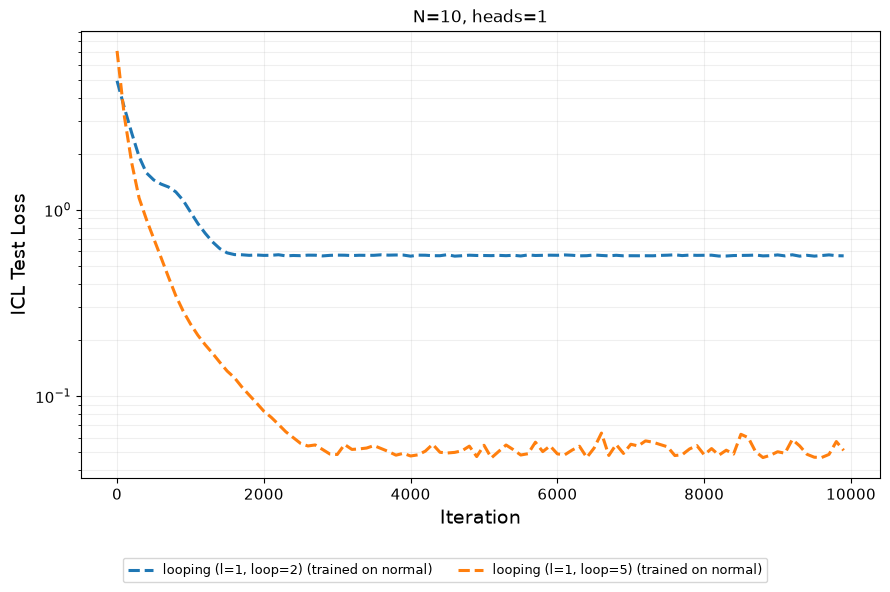

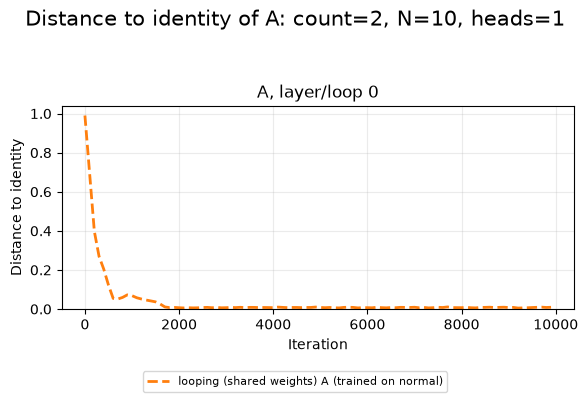

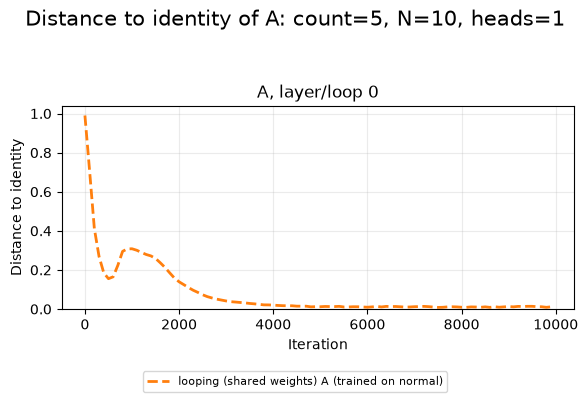

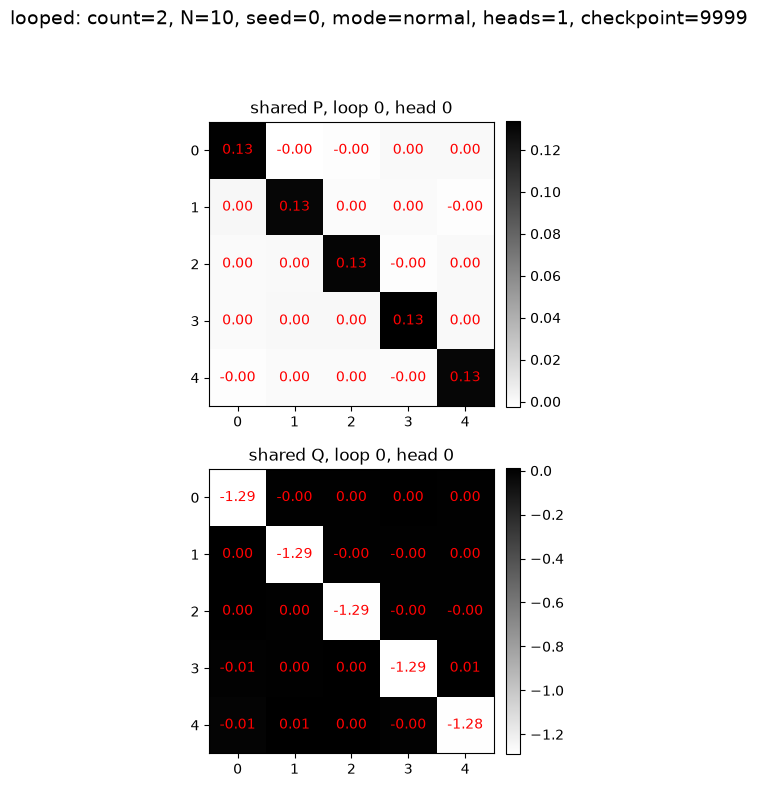

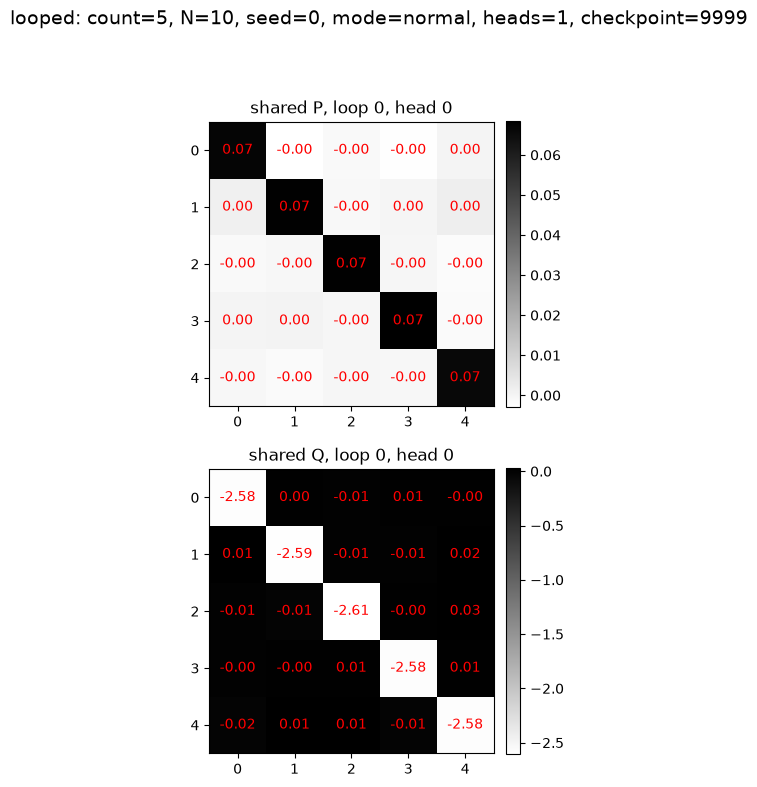

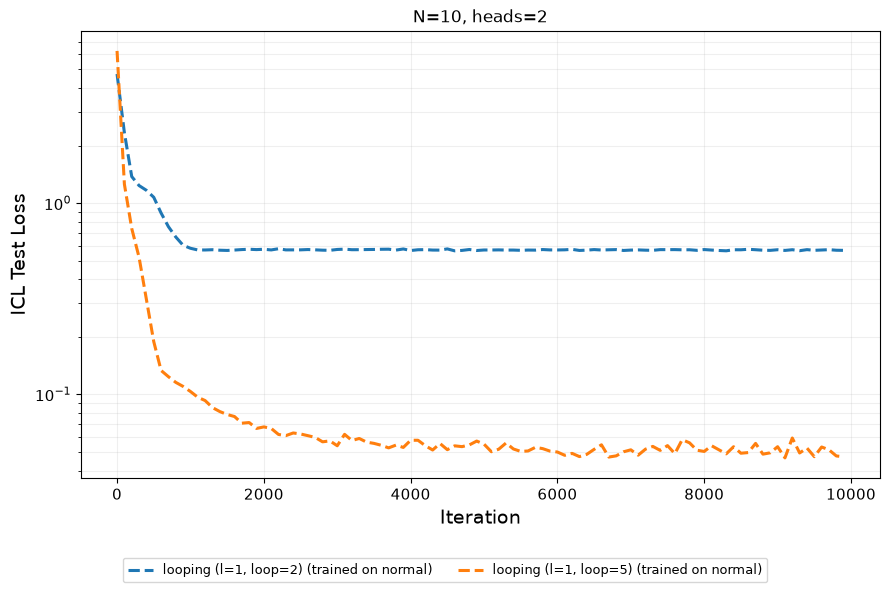

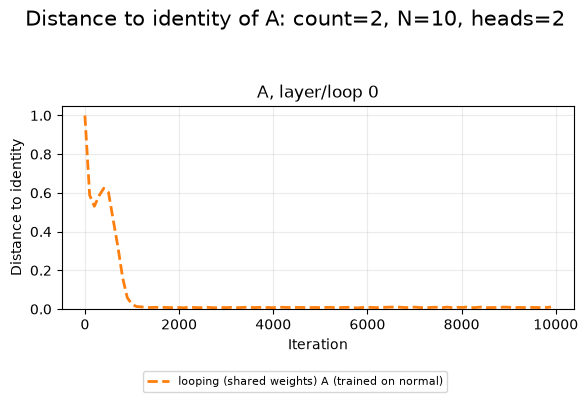

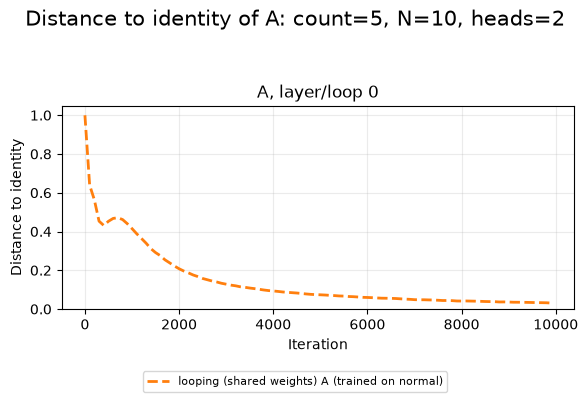

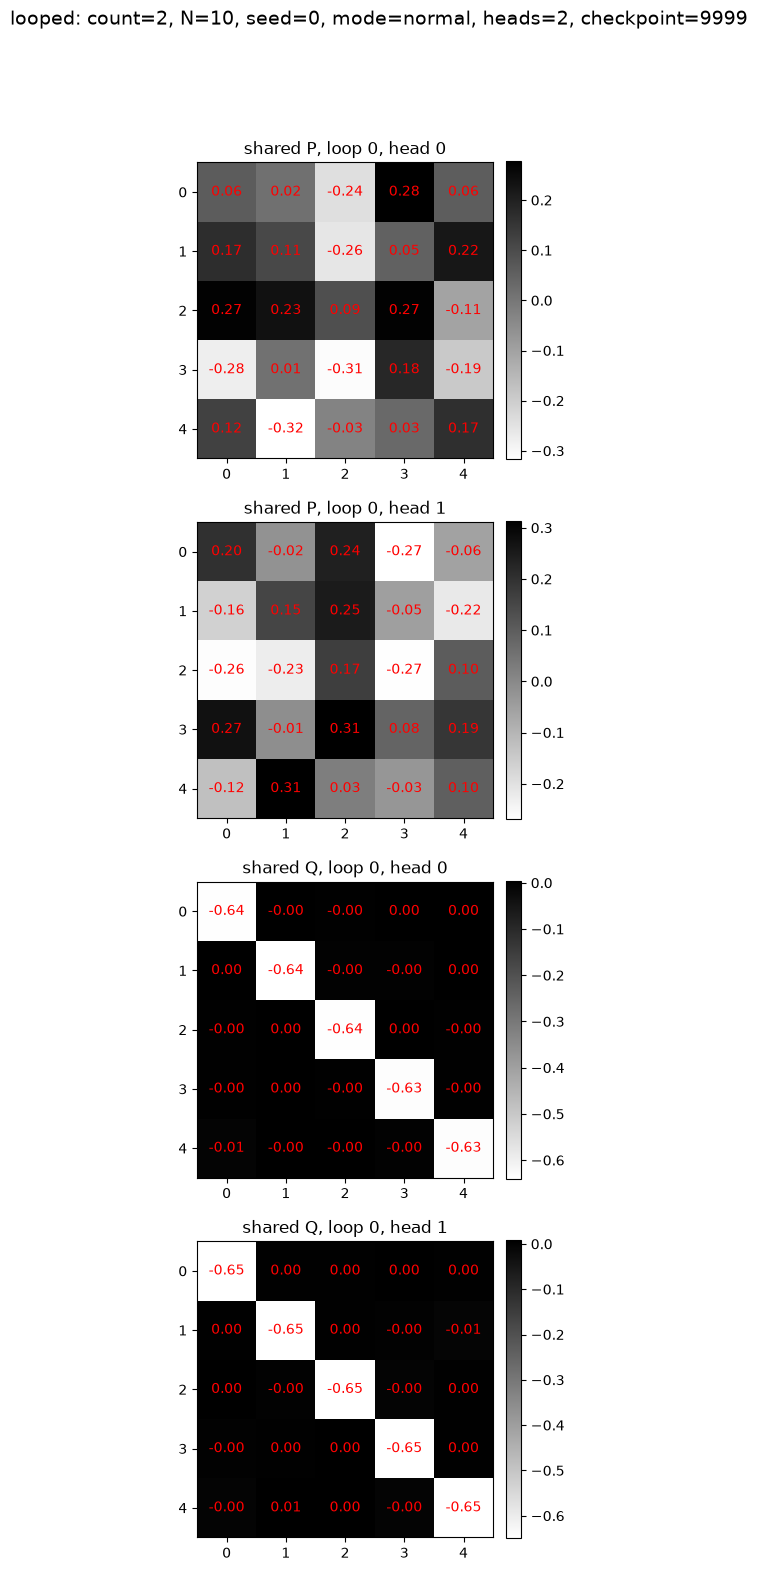

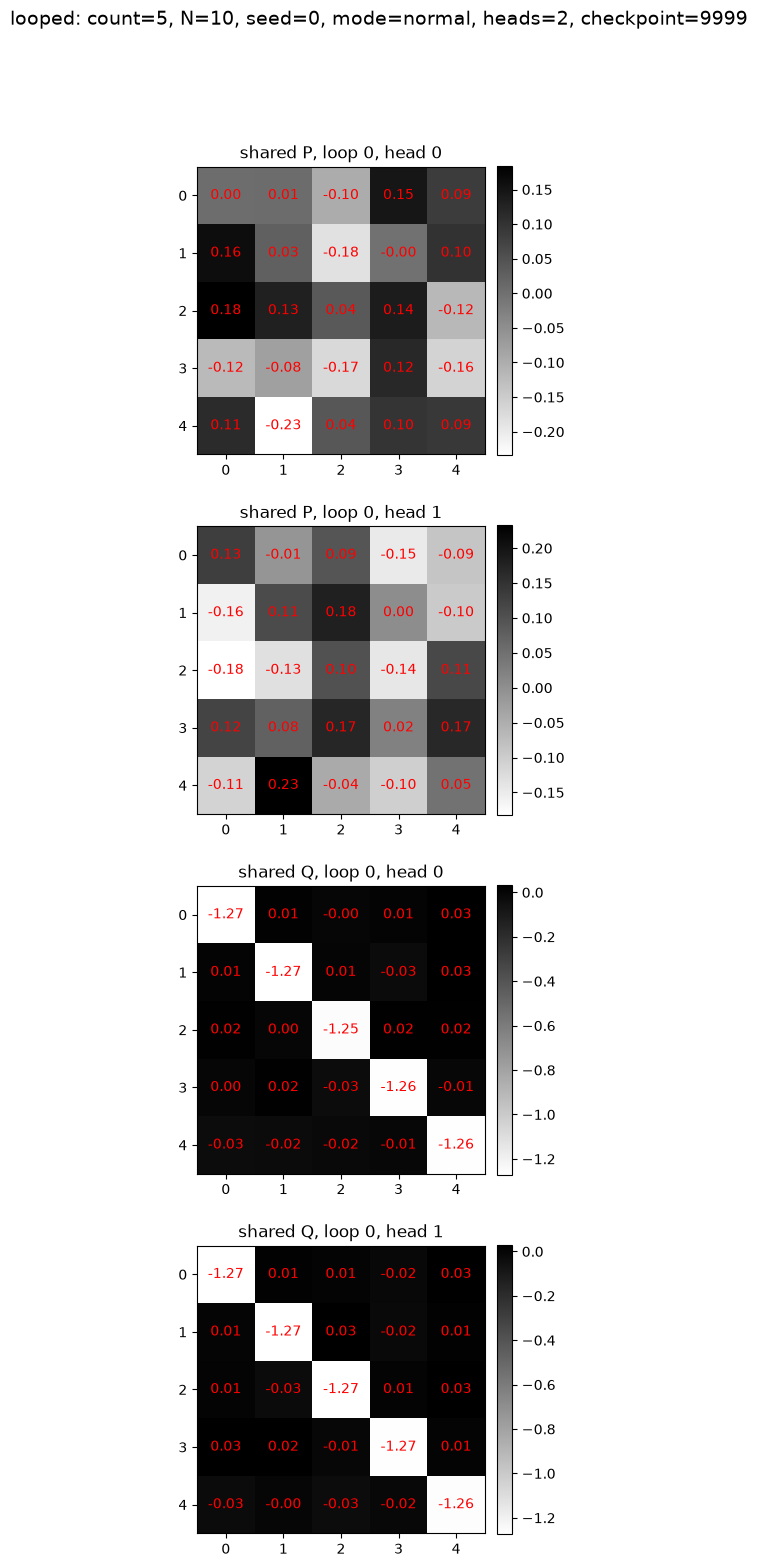

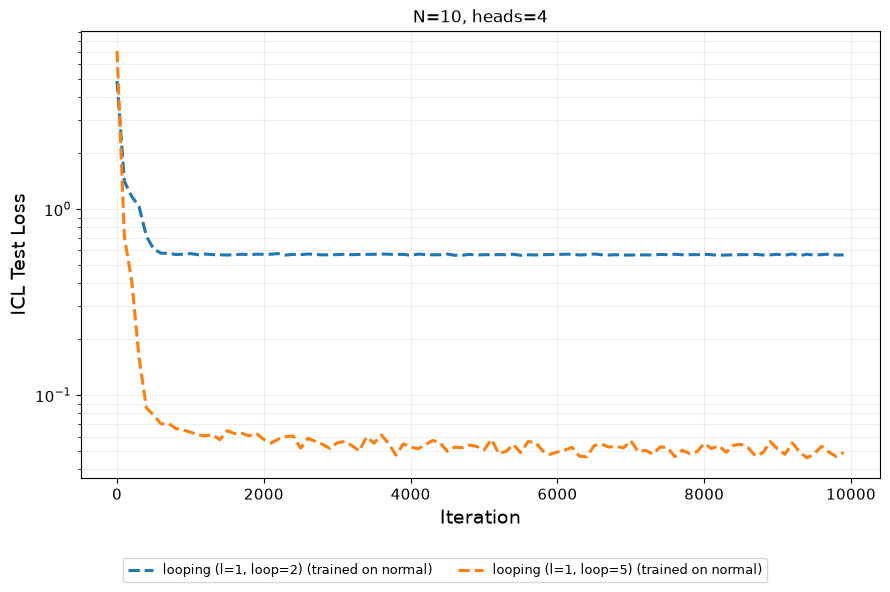

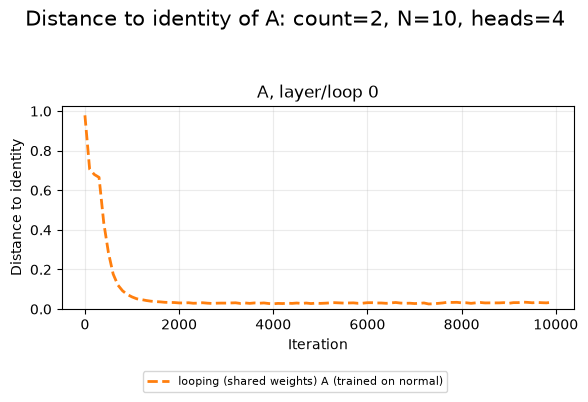

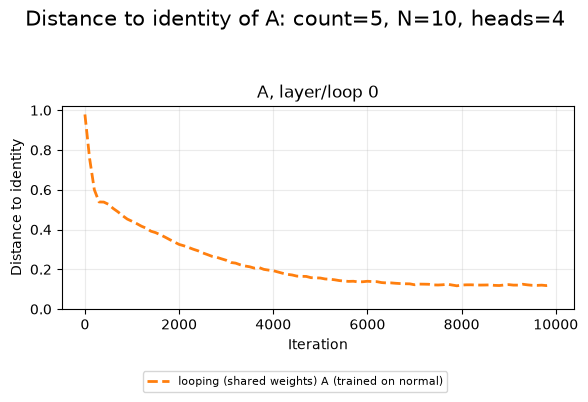

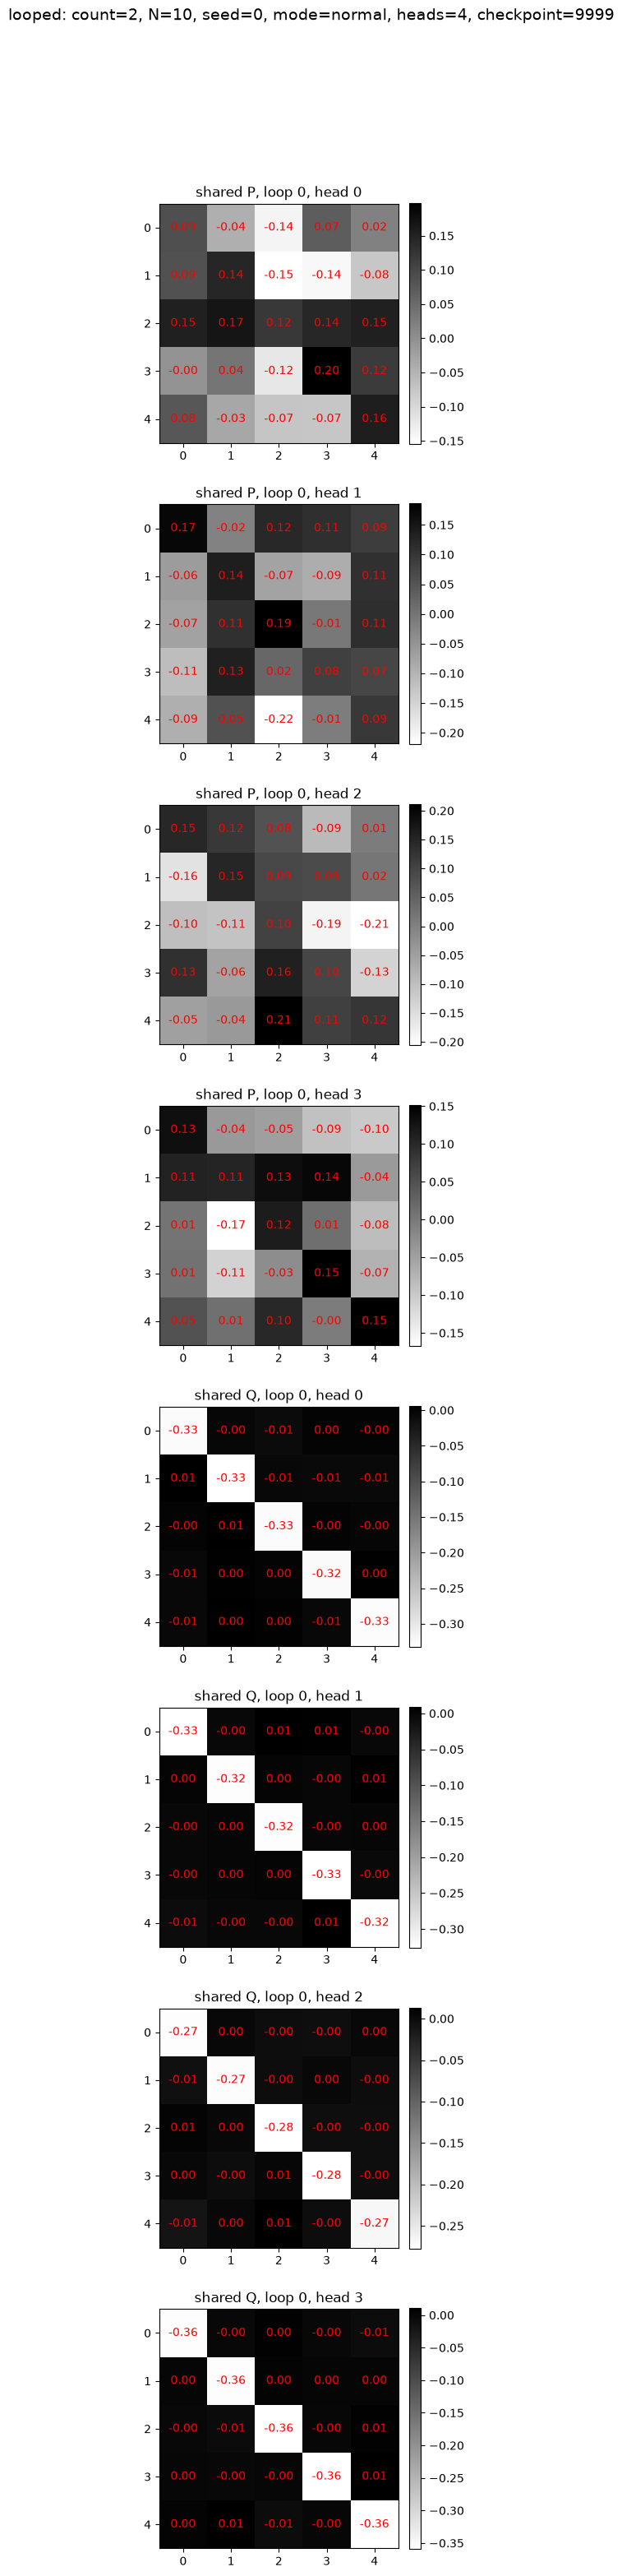

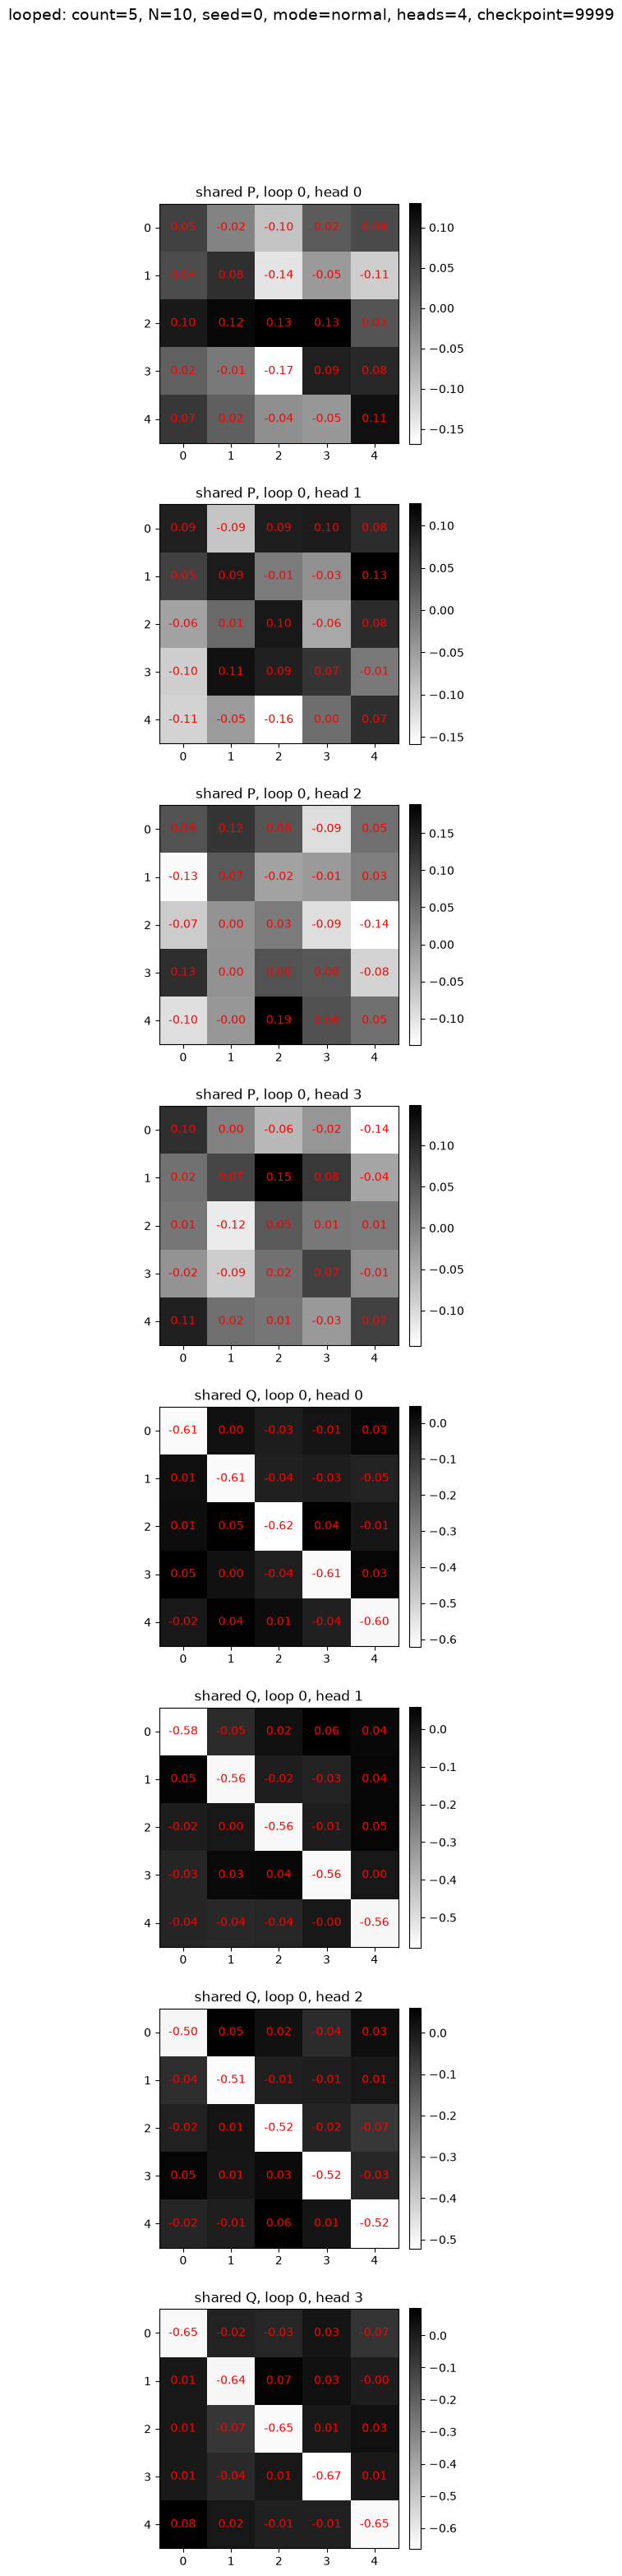

In [29]:
# Use the notebook's standard convergence, distance, and parameter plotting helpers.
multihead_plot_dir = os.path.join('figures', 'looped_multihead')
multihead_iterations = np.arange(0, max_iters, stride)

for head_count in multihead_head_counts:
    head_hist_dict = {
        key: history for key, history in multihead_hist_dict.items()
        if len(key) > 5 and key[5] == head_count
    }
    head_loss_dict = {
        key: losses for key, losses in multihead_loss_dict.items()
        if len(key) > 5 and key[5] == head_count
    }
    head_fig_dir = os.path.join(multihead_plot_dir, f'{head_count}_heads')
    os.makedirs(head_fig_dir, exist_ok=True)

    plot_loss_curves(
        head_loss_dict,
        multihead_loop_counts,
        multihead_model_types,
        multihead_iterations,
        fig_dir=head_fig_dir,
        filename='held_out_loss.pdf',
        seeds=multihead_seeds,
        head_count=head_count,
    )

    head_dist_dict = compute_dist_dict(
        head_hist_dict,
        multihead_iterations,
        n_head=head_count,
        hist_stride=hist_stride,
    )
    plot_dist_to_identity(
        head_dist_dict,
        multihead_loop_counts,
        multihead_iterations,
        fig_dir=head_fig_dir,
        head_count=head_count,
    )

    plot_parameter_matrices(
        head_hist_dict,
        multihead_seeds[0],
        multihead_loop_counts,
        multihead_model_types,
        n_head=head_count,
        hist_stride=hist_stride,
        fig_dir=head_fig_dir,
        head_count=head_count,
    )
